First 5 rows of the dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnanc

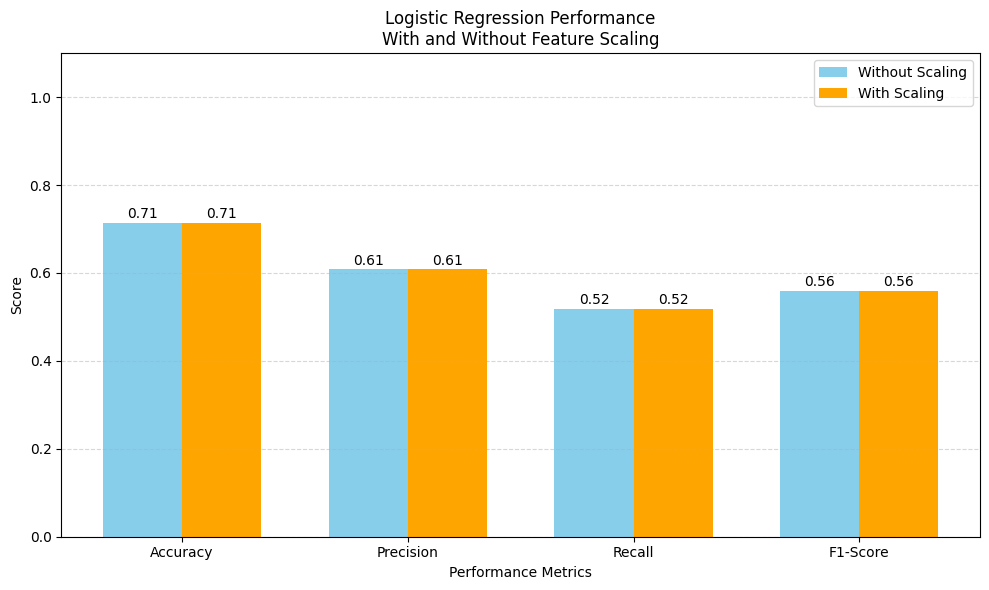

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv(url, names=columns)


print("First 5 rows of the dataset:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

print("\nDataset Information:")
print(data.info())


print("\nMissing Values:")
print(data.isnull().sum())


X = data.drop("Outcome", axis=1)
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


model_without_scaling = LogisticRegression(max_iter=1000)

# Train the model
model_without_scaling.fit(X_train, y_train)

# Make predictions
y_pred_without = model_without_scaling.predict(X_test)


# Calculate metrics
accuracy_without = accuracy_score(y_test, y_pred_without)

precision_without = precision_score(
    y_test,
    y_pred_without,
    zero_division=0
)

recall_without = recall_score(
    y_test,
    y_pred_without,
    zero_division=0
)

f1_without = f1_score(
    y_test,
    y_pred_without,
    zero_division=0
)

scaler = StandardScaler()

# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply same scaler to test data
X_test_scaled = scaler.transform(X_test)

model_with_scaling = LogisticRegression(max_iter=1000)

# Train the model
model_with_scaling.fit(X_train_scaled, y_train)

# Make predictions
y_pred_with = model_with_scaling.predict(X_test_scaled)


# Calculate metrics
accuracy_with = accuracy_score(y_test, y_pred_with)

precision_with = precision_score(
    y_test,
    y_pred_with,
    zero_division=0
)

recall_with = recall_score(
    y_test,
    y_pred_with,
    zero_division=0
)

f1_with = f1_score(
    y_test,
    y_pred_with,
    zero_division=0
)

results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Without Scaling": [
        accuracy_without,
        precision_without,
        recall_without,
        f1_without
    ],

    "With Scaling": [
        accuracy_with,
        precision_with,
        recall_with,
        f1_with
    ]
})


print("\n")
print("=" * 65)
print("             PERFORMANCE COMPARISON")
print("=" * 65)

print(results.to_string(index=False))


print("\n")
print("=" * 65)
print("                RESULTS IN PERCENTAGE")
print("=" * 65)

for i in range(len(results)):

    metric = results.loc[i, "Metric"]

    without_scaling = (
        results.loc[i, "Without Scaling"] * 100
    )

    with_scaling = (
        results.loc[i, "With Scaling"] * 100
    )

    print(
        f"{metric:<12} : "
        f"Without Scaling = {without_scaling:.2f}%   "
        f"With Scaling = {with_scaling:.2f}%"
    )


metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

without_values = [
    accuracy_without,
    precision_without,
    recall_without,
    f1_without
]

with_values = [
    accuracy_with,
    precision_with,
    recall_with,
    f1_with
]


# Position of bars
x = range(len(metrics))

# Width of each bar
width = 0.35


# Create figure
plt.figure(figsize=(10, 6))


# Plot bars
plt.bar(
    [i - width / 2 for i in x],
    without_values,
    width=width,
    label="Without Scaling",
    color="skyblue"
)

plt.bar(
    [i + width / 2 for i in x],
    with_values,
    width=width,
    label="With Scaling",
    color="orange"
)

for i, value in enumerate(without_values):
    plt.text(
        i - width / 2,
        value + 0.01,
        f"{value:.2f}",
        ha="center",
        fontsize=10
    )

for i, value in enumerate(with_values):
    plt.text(
        i + width / 2,
        value + 0.01,
        f"{value:.2f}",
        ha="center",
        fontsize=10
    )


plt.xlabel("Performance Metrics")
plt.ylabel("Score")

plt.title(
    "Logistic Regression Performance\n"
    "With and Without Feature Scaling"
)

plt.xticks(
    list(x),
    metrics
)

plt.ylim(0, 1.1)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

# Display graph
plt.show()
